In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('sales_data.csv')

df.head()

,OrderID,Product,Category,City,OrderDate,Quantity,UnitPrice
0,101,Laptop,Electronics,Chennai,2026-01-05,2,50000
1,102,Mouse,Accessories,Bangalore,2026-01-08,5,500
2,103,Keyboard,Accessories,Hyderabad,2026-01-12,3,1200
3,104,Monitor,Electronics,Chennai,2026-02-03,2,15000
4,105,Laptop,Electronics,Bangalore,2026-02-10,1,50000


In [2]:
df.shape

(15, 7)

In [3]:
df.columns

Index(['OrderID', 'Product', 'Category', 'City', 'OrderDate', 'Quantity',
       'UnitPrice'],
      dtype='object')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   OrderID    15 non-null     int64 
 1   Product    15 non-null     object
 2   Category   15 non-null     object
 3   City       15 non-null     object
 4   OrderDate  15 non-null     object
 5   Quantity   15 non-null     int64 
 6   UnitPrice  15 non-null     int64 
dtypes: int64(3), object(4)
memory usage: 968.0+ bytes


In [5]:
df.describe()

,OrderID,Quantity,UnitPrice
count,15.000000,15.000000,15.000000
mean,108.000000,3.333333,19460.000000
std,4.472136,2.581989,18219.408803
min,101.000000,1.000000,500.000000
25%,104.500000,2.000000,1200.000000
50%,108.000000,3.000000,18000.000000
75%,111.500000,3.500000,25000.000000
max,115.000000,10.000000,50000.000000


In [6]:
df.isnull().sum()

OrderID      0
Product      0
Category     0
City         0
OrderDate    0
Quantity     0
UnitPrice    0
dtype: int64

In [7]:
df.tail()

,OrderID,Product,Category,City,OrderDate,Quantity,UnitPrice
10,111,Phone,Electronics,Bangalore,2026-04-05,3,18000
11,112,Laptop,Electronics,Chennai,2026-04-12,1,50000
12,113,Mouse,Accessories,Hyderabad,2026-05-03,10,500
13,114,Printer,Electronics,Bangalore,2026-05-10,1,25000
14,115,Tablet,Electronics,Chennai,2026-05-18,3,20000


In [8]:
df['Quantity'].sum()

50

In [9]:
df['Quantity'].mean()

3.3333333333333335

In [10]:
df['Quantity'].min()

1

In [11]:
df['Quantity'].max()

10

In [12]:
df['OrderID'].count()

15

In [13]:
df['UnitPrice'].sum()

291900

In [14]:
df['UnitPrice'].mean()

19460.0

In [15]:
df['UnitPrice'].max()

50000

In [16]:
df['UnitPrice'].min()

500

In [17]:
df['Revenue'] = df['Quantity'] * df['UnitPrice']

In [18]:
df.head()

,OrderID,Product,Category,City,OrderDate,Quantity,UnitPrice,Revenue
0,101,Laptop,Electronics,Chennai,2026-01-05,2,50000,100000
1,102,Mouse,Accessories,Bangalore,2026-01-08,5,500,2500
2,103,Keyboard,Accessories,Hyderabad,2026-01-12,3,1200,3600
3,104,Monitor,Electronics,Chennai,2026-02-03,2,15000,30000
4,105,Laptop,Electronics,Bangalore,2026-02-10,1,50000,50000


In [19]:
df['Revenue'].sum()

523900

In [20]:
df['Revenue'].mean()

34926.666666666664

In [21]:
df['Revenue'].max()

100000

In [22]:
df['Revenue'].min()

2500

In [23]:
df[['Product', 'Quantity', 'UnitPrice', 'Revenue']]

,Product,Quantity,UnitPrice,Revenue
0,Laptop,2,50000,100000
1,Mouse,5,500,2500
2,Keyboard,3,1200,3600
3,Monitor,2,15000,30000
4,Laptop,1,50000,50000
5,Mouse,8,500,4000
6,Printer,2,25000,50000
7,Keyboard,4,1200,4800
8,Monitor,3,15000,45000
9,Tablet,2,20000,40000


In [24]:
df[df['Revenue'] > 10000]

,OrderID,Product,Category,City,OrderDate,Quantity,UnitPrice,Revenue
0,101,Laptop,Electronics,Chennai,2026-01-05,2,50000,100000
3,104,Monitor,Electronics,Chennai,2026-02-03,2,15000,30000
4,105,Laptop,Electronics,Bangalore,2026-02-10,1,50000,50000
6,107,Printer,Electronics,Hyderabad,2026-03-02,2,25000,50000
8,109,Monitor,Electronics,Chennai,2026-03-15,3,15000,45000
9,110,Tablet,Electronics,Hyderabad,2026-04-01,2,20000,40000
10,111,Phone,Electronics,Bangalore,2026-04-05,3,18000,54000
11,112,Laptop,Electronics,Chennai,2026-04-12,1,50000,50000
13,114,Printer,Electronics,Bangalore,2026-05-10,1,25000,25000
14,115,Tablet,Electronics,Chennai,2026-05-18,3,20000,60000


In [25]:
df[df['Quantity'] > 2]

,OrderID,Product,Category,City,OrderDate,Quantity,UnitPrice,Revenue
1,102,Mouse,Accessories,Bangalore,2026-01-08,5,500,2500
2,103,Keyboard,Accessories,Hyderabad,2026-01-12,3,1200,3600
5,106,Mouse,Accessories,Chennai,2026-02-15,8,500,4000
7,108,Keyboard,Accessories,Bangalore,2026-03-08,4,1200,4800
8,109,Monitor,Electronics,Chennai,2026-03-15,3,15000,45000
10,111,Phone,Electronics,Bangalore,2026-04-05,3,18000,54000
12,113,Mouse,Accessories,Hyderabad,2026-05-03,10,500,5000
14,115,Tablet,Electronics,Chennai,2026-05-18,3,20000,60000


In [26]:
product_revenue = df.groupby('Product')['Revenue'].sum()

product_revenue

Product
Keyboard      8400
Laptop      200000
Monitor      75000
Mouse        11500
Phone        54000
Printer      75000
Tablet      100000
Name: Revenue, dtype: int64

In [27]:
product_revenue.idxmax()

'Laptop'

In [28]:
city_revenue = df.groupby('City')['Revenue'].sum()

city_revenue

City
Bangalore    136300
Chennai      289000
Hyderabad     98600
Name: Revenue, dtype: int64

In [29]:
city_revenue.idxmax()

'Chennai'

In [30]:
df.groupby('Product')['Quantity'].sum()

Product
Keyboard     7
Laptop       4
Monitor      5
Mouse       23
Phone        3
Printer      3
Tablet       5
Name: Quantity, dtype: int64

In [31]:
df[df['UnitPrice'] > 20000]

,OrderID,Product,Category,City,OrderDate,Quantity,UnitPrice,Revenue
0,101,Laptop,Electronics,Chennai,2026-01-05,2,50000,100000
4,105,Laptop,Electronics,Bangalore,2026-02-10,1,50000,50000
6,107,Printer,Electronics,Hyderabad,2026-03-02,2,25000,50000
11,112,Laptop,Electronics,Chennai,2026-04-12,1,50000,50000
13,114,Printer,Electronics,Bangalore,2026-05-10,1,25000,25000


In [32]:
df['OrderDate'].dtype

dtype('O')

In [33]:
df['OrderDate'] = pd.to_datetime(df['OrderDate'])

In [34]:
df['OrderDate'].dtype

dtype('<M8[ns]')

In [35]:
df[['OrderID', 'OrderDate']].head()

,OrderID,OrderDate
0,101,2026-01-05
1,102,2026-01-08
2,103,2026-01-12
3,104,2026-02-03
4,105,2026-02-10


In [36]:
df['Year'] = df['OrderDate'].dt.year

df['Month'] = df['OrderDate'].dt.month

df['Day'] = df['OrderDate'].dt.day

In [37]:
df.head()

,OrderID,Product,Category,City,OrderDate,Quantity,UnitPrice,Revenue,Year,Month,Day
0,101,Laptop,Electronics,Chennai,2026-01-05,2,50000,100000,2026,1,5
1,102,Mouse,Accessories,Bangalore,2026-01-08,5,500,2500,2026,1,8
2,103,Keyboard,Accessories,Hyderabad,2026-01-12,3,1200,3600,2026,1,12
3,104,Monitor,Electronics,Chennai,2026-02-03,2,15000,30000,2026,2,3
4,105,Laptop,Electronics,Bangalore,2026-02-10,1,50000,50000,2026,2,10


In [38]:
daily_revenue = df.groupby('Day')['Revenue'].sum()

daily_revenue

Day
1      40000
2      50000
3      35000
5     154000
8       7300
10     75000
12     53600
15     49000
18     60000
Name: Revenue, dtype: int64

In [39]:
monthly_revenue = df.groupby('Month')['Revenue'].sum()

monthly_revenue

Month
1    106100
2     84000
3     99800
4    144000
5     90000
Name: Revenue, dtype: int64

In [40]:
yearly_revenue = df.groupby('Year')['Revenue'].sum()

yearly_revenue

Year
2026    523900
Name: Revenue, dtype: int64

In [41]:
monthly_revenue.idxmax()

4

In [42]:
daily_revenue.idxmax()

5

In [43]:
df.groupby('Month')['Quantity'].sum()

Month
1    10
2    11
3     9
4     6
5    14
Name: Quantity, dtype: int64

In [44]:
df.groupby('Month').agg({
    'Quantity': 'sum',
    'Revenue': 'sum',
    'OrderID': 'count'
})

,Quantity,Revenue,OrderID
Month,,,
1,10,106100,3
2,11,84000,3
3,9,99800,3
4,6,144000,3
5,14,90000,3


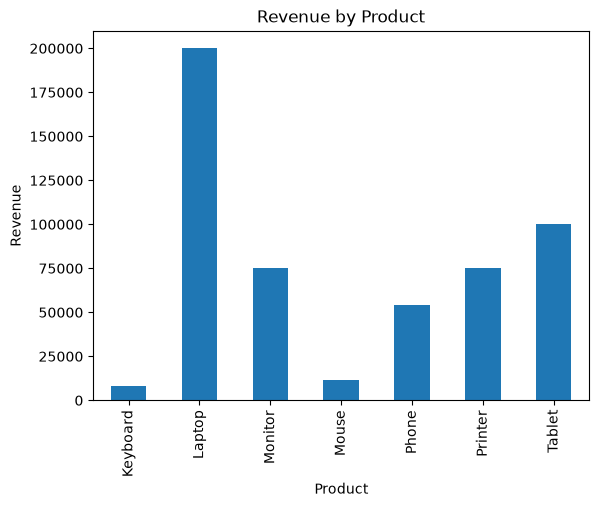

In [45]:
product_revenue.plot(kind='bar')

plt.title('Revenue by Product')
plt.xlabel('Product')
plt.ylabel('Revenue')
plt.show()

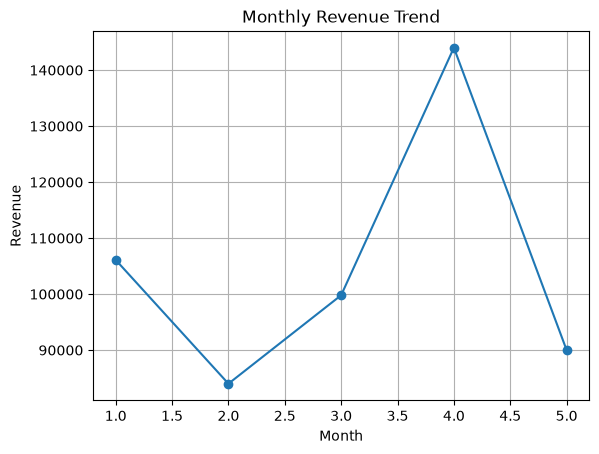

In [46]:
monthly_revenue.plot(kind='line', marker='o')

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.grid()
plt.show()

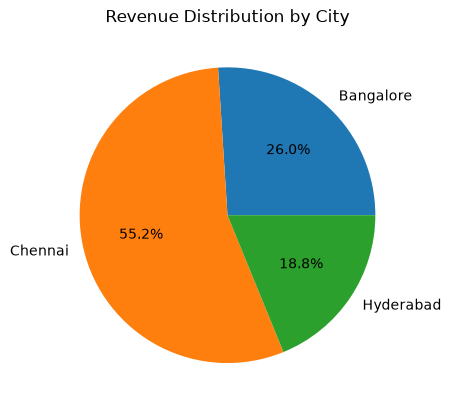

In [47]:
city_revenue.plot(kind='pie', autopct='%1.1f%%')

plt.title('Revenue Distribution by City')
plt.ylabel('')
plt.show()